# Second-Hand Fashion: What Drives Resale Price and Speed of Sale?

**Questions**
1. How much of the original retail price does a second-hand item keep, and how does that change by brand tier and condition?
2. Which listings sell, and how fast?
3. Can a simple model predict a fair listing price?

**Data:** `data/listings.csv` contains 4,000+ simulated second-hand fashion listings (brand, category, condition, photos, prices, whether and when the item sold). The data is synthetic and was generated with `data/generate_data.py`, with some data quality problems added on purpose to practise cleaning.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

## 1. Load and inspect the data

In [2]:
df = pd.read_csv("data/listings.csv")
print(df.shape)
df.head()

(4030, 12)


,listing_id,brand,brand_tier,category,condition,photos,original_price_eur,listing_price_eur,listed_date,seller_country,sold,days_to_sell
0,103808,H&M,high street,Jackets,New without tags,1,43.32,31.0,2025-08-31,Poland,True,8.0
1,100162,Gucci,luxury,Jackets,Satisfactory,7,1199.97,354.0,2025-04-20,Germany,True,11.0
2,103657,Adidas,sportswear,Coats,Satisfactory,4,200.41,24.0,2025-02-02,Poland,True,23.0
3,102013,H&M,high street,Bags,New without tags,8,46.29,23.0,2025-01-26,Lithuania,True,3.0
4,103012,H&M,high street,Dresses,Very good,5,26.02,8.0,2025-03-04,Germany,False,NaN


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4030 entries, 0 to 4029
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   listing_id          4030 non-null   int64  
 1   brand               4030 non-null   str    
 2   brand_tier          4030 non-null   str    
 3   category            4030 non-null   str    
 4   condition           4030 non-null   str    
 5   photos              4030 non-null   int64  
 6   original_price_eur  3990 non-null   float64
 7   listing_price_eur   4030 non-null   float64
 8   listed_date         4030 non-null   str    
 9   seller_country      4030 non-null   str    
 10  sold                4030 non-null   bool   
 11  days_to_sell        2334 non-null   float64
dtypes: bool(1), float64(3), int64(2), str(6)
memory usage: 350.4 KB


In [4]:
# Missing values per column
df.isna().sum()

listing_id               0
brand                    0
brand_tier               0
category                 0
condition                0
photos                   0
original_price_eur      40
listing_price_eur        0
listed_date              0
seller_country           0
sold                     0
days_to_sell          1696
dtype: int64

## 2. Clean the data

Four problems to fix:
- duplicate rows
- brand names written in different ways (for example `ZARA`, `zara `, `Zara`)
- missing original prices
- a few listing prices that look like typos (far above the original price)

In [5]:
# 2.1 Duplicates
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

Duplicate rows: 30


In [6]:
# 2.2 Brand names: strip spaces, then map every spelling to one standard name
print("Unique brand spellings before:", df["brand"].nunique())
# Most common spelling of each brand becomes the standard one
clean = df["brand"].str.strip()
standard = clean.groupby(clean.str.lower()).agg(lambda s: s.mode()[0])
df["brand"] = clean.str.lower().map(standard)
print("Unique brands after:", df["brand"].nunique())

Unique brand spellings before: 41
Unique brands after: 17


In [7]:
# 2.3 Missing original prices: fill with the median for the same brand and category
missing_before = df["original_price_eur"].isna().sum()
df["original_price_eur"] = df.groupby(["brand", "category"])["original_price_eur"].transform(
    lambda s: s.fillna(s.median()))
print(f"Filled {missing_before} missing original prices")

Filled 40 missing original prices


In [8]:
# 2.4 Price typos: a second-hand item listed at more than 3x its retail price is almost certainly an error
df["price_ratio"] = df["listing_price_eur"] / df["original_price_eur"]
typos = df[df["price_ratio"] > 3]
print(f"Suspicious listings: {len(typos)}")
display(typos[["brand", "category", "original_price_eur", "listing_price_eur"]])
df = df[df["price_ratio"] <= 3].copy()
print("Rows after cleaning:", len(df))

Suspicious listings: 6


,brand,category,original_price_eur,listing_price_eur
471,Mango,Jumpers,54.91,1900.0
2342,Tommy Hilfiger,Jeans,100.86,4400.0
2439,The North Face,Coats,453.61,7300.0
3205,Levi's,T-shirts,44.25,1000.0
3740,Levi's,Jeans,81.75,3600.0
3804,Zara,Coats,107.13,2700.0


Rows after cleaning: 3994


## 3. How much value does an item keep?

`price_ratio` = listing price / original retail price.

In [9]:
tier_order = ["high street", "sportswear", "premium", "luxury"]
cond_order = ["New with tags", "New without tags", "Very good", "Good", "Satisfactory"]

pivot = (df.pivot_table(index="condition", columns="brand_tier", values="price_ratio", aggfunc="median")
           .loc[cond_order, tier_order])
(pivot * 100).round(0)

brand_tier,high street,sportswear,premium,luxury
condition,,,,
New with tags,53.0,63.0,66.0,77.0
New without tags,45.0,52.0,56.0,71.0
Very good,34.0,40.0,44.0,54.0
Good,26.0,30.0,33.0,40.0
Satisfactory,16.0,20.0,22.0,23.0


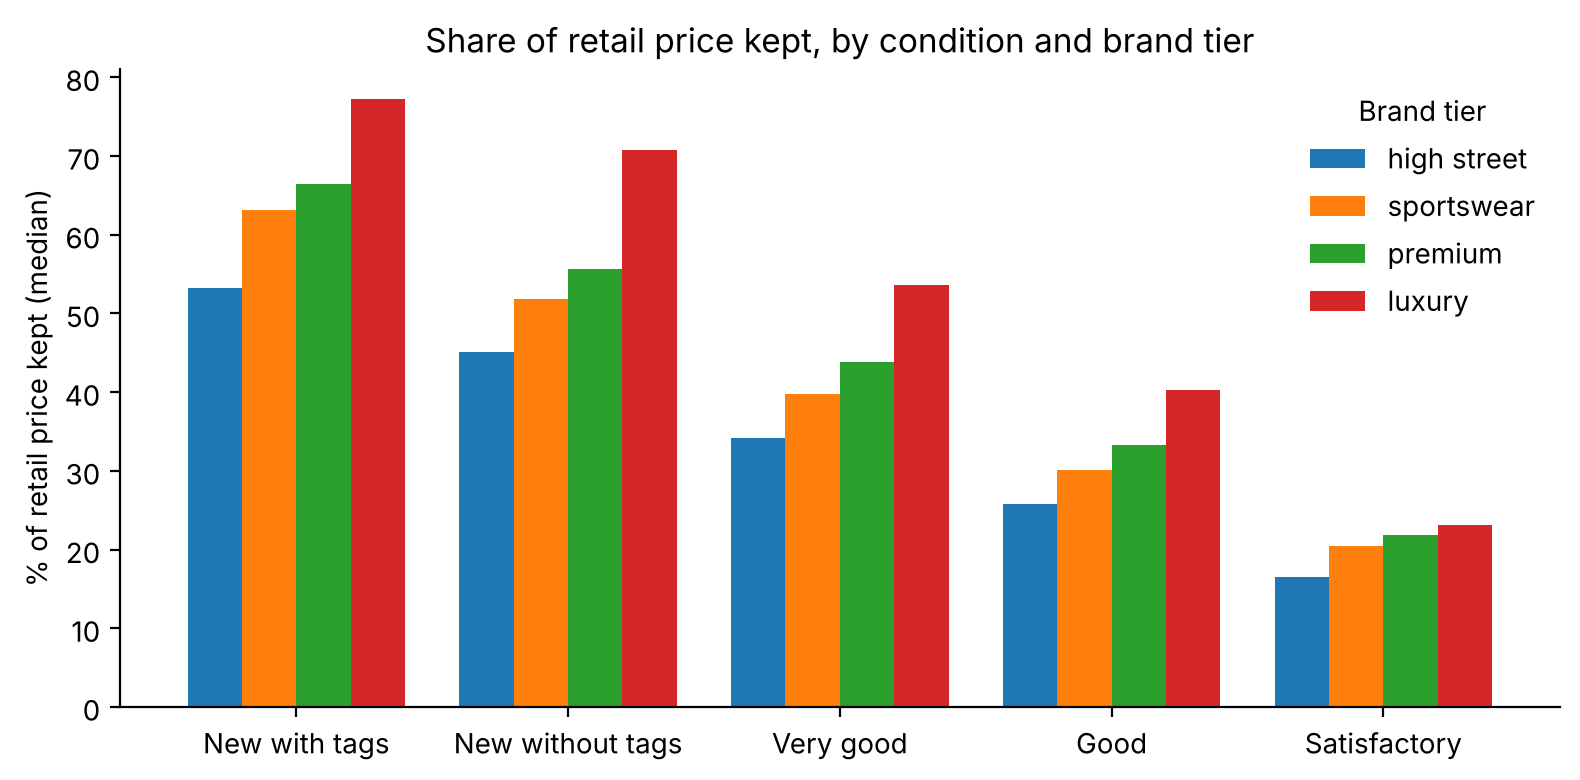

In [10]:
ax = (pivot * 100).plot(kind="bar", rot=0, width=0.8)
ax.set_ylabel("% of retail price kept (median)")
ax.set_xlabel("")
ax.set_title("Share of retail price kept, by condition and brand tier")
ax.legend(title="Brand tier", frameon=False)
plt.tight_layout()
plt.show()

In [11]:
# Brands that keep the most value (at least 50 listings)
brand_stats = (df.groupby("brand")
                 .agg(listings=("listing_id", "count"), median_ratio=("price_ratio", "median"))
                 .query("listings >= 50")
                 .sort_values("median_ratio", ascending=False))
brand_stats["median_ratio"] = (brand_stats["median_ratio"] * 100).round(0)
brand_stats.head(10)

,listings,median_ratio
brand,,
Gucci,51,46.0
COS,150,43.0
Levi's,239,43.0
Tommy Hilfiger,171,41.0
The North Face,194,39.0
Ralph Lauren,138,38.0
Nike,338,37.0
Adidas,310,35.0
Puma,182,35.0


## 4. Which listings sell, and how fast?

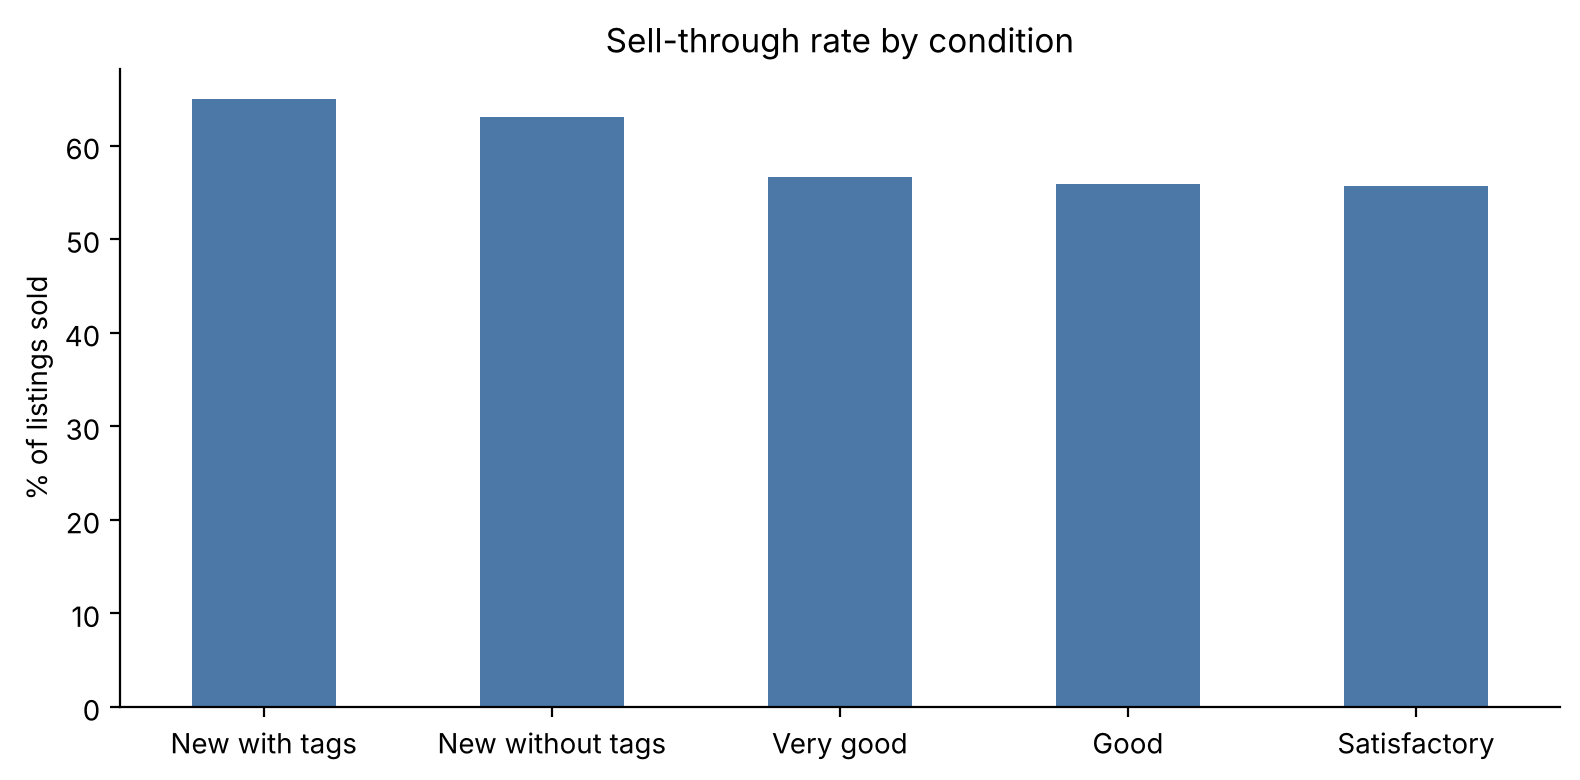

In [12]:
sell_by_cond = df.groupby("condition")["sold"].mean().loc[cond_order] * 100
ax = sell_by_cond.plot(kind="bar", rot=0, color="#4C78A8")
ax.set_ylabel("% of listings sold")
ax.set_xlabel("")
ax.set_title("Sell-through rate by condition")
plt.tight_layout()
plt.show()

In [13]:
photo_stats = df.groupby("photos").agg(sell_rate=("sold", "mean"),
                                      median_days=("days_to_sell", "median"))
photo_stats["sell_rate"] = (photo_stats["sell_rate"] * 100).round(1)
photo_stats

,sell_rate,median_days
photos,,
1,45.7,12.0
2,44.6,10.0
3,54.0,10.0
4,57.6,9.0
5,60.1,8.0
6,61.4,8.0
7,68.4,8.0
8,69.5,6.0


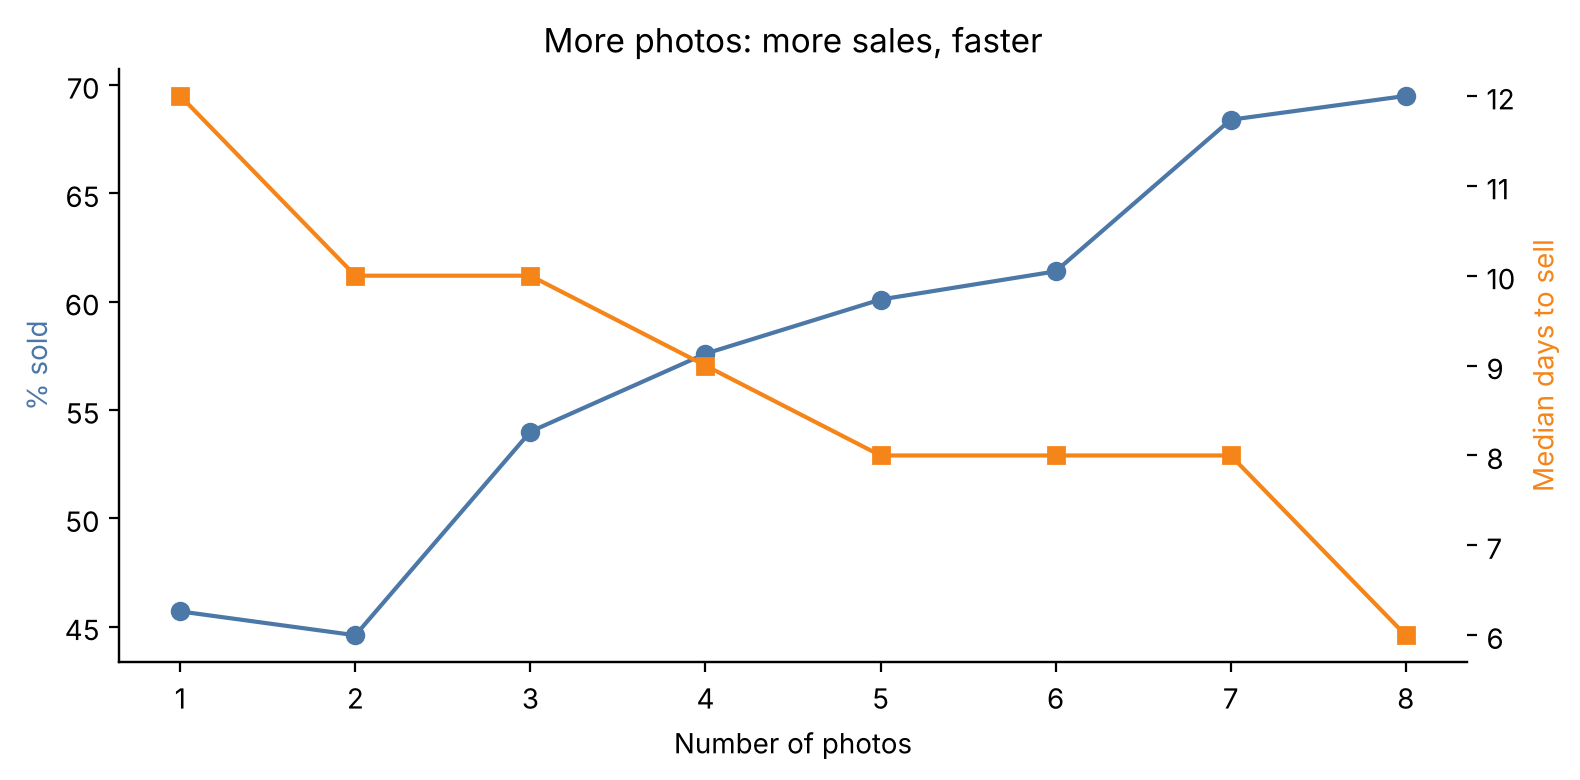

In [14]:
fig, ax1 = plt.subplots()
ax1.plot(photo_stats.index, photo_stats["sell_rate"], marker="o", color="#4C78A8")
ax1.set_xlabel("Number of photos")
ax1.set_ylabel("% sold", color="#4C78A8")
ax2 = ax1.twinx()
ax2.plot(photo_stats.index, photo_stats["median_days"], marker="s", color="#F58518")
ax2.set_ylabel("Median days to sell", color="#F58518")
ax1.set_title("More photos: more sales, faster")
plt.tight_layout()
plt.show()

In [15]:
# Does pricing above a 'fair' level slow things down?
# Fair level = median price_ratio for the same tier and condition.
df["fair_ratio"] = df.groupby(["brand_tier", "condition"])["price_ratio"].transform("median")
df["pricing"] = pd.cut(df["price_ratio"] / df["fair_ratio"], bins=[0, 0.9, 1.1, 10],
                       labels=["Below fair", "Around fair", "Above fair"])
df.groupby("pricing", observed=True).agg(listings=("listing_id", "count"),
                                         sell_rate=("sold", "mean"),
                                         median_days=("days_to_sell", "median")).round(2)

,listings,sell_rate,median_days
pricing,,,
Below fair,1357,0.66,7.0
Around fair,1266,0.59,8.0
Above fair,1371,0.49,12.0


## 5. Predicting a fair listing price

A linear regression on the log of the listing price. Using logs means the model works with percentages
(for example "Good condition lowers price by about X%"), which suits prices that range from €2 to €1,000+.

In [16]:
features = ["brand_tier", "category", "condition", "photos"]
X = pd.get_dummies(df[features], drop_first=True)
X["log_original_price"] = np.log(df["original_price_eur"])
y = np.log(df["listing_price_eur"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression().fit(X_train, y_train)

pred = np.exp(model.predict(X_test))
actual = np.exp(y_test)
print(f"R² (log price): {r2_score(y_test, model.predict(X_test)):.2f}")
print(f"Mean absolute error: €{mean_absolute_error(actual, pred):.2f}")
print(f"Median listing price in test set: €{actual.median():.2f}")

R² (log price): 0.94
Mean absolute error: €9.34
Median listing price in test set: €22.00


In [17]:
# Effect of condition compared with 'Good' (the baseline after dummy encoding)
coefs = pd.Series(model.coef_, index=X.columns)
cond_effect = coefs[coefs.index.str.startswith("condition_")]
(np.exp(cond_effect) - 1).mul(100).round(0).rename("% price difference vs 'Good'")

condition_New with tags       102.0
condition_New without tags     78.0
condition_Satisfactory        -34.0
condition_Very good            32.0
Name: % price difference vs 'Good', dtype: float64

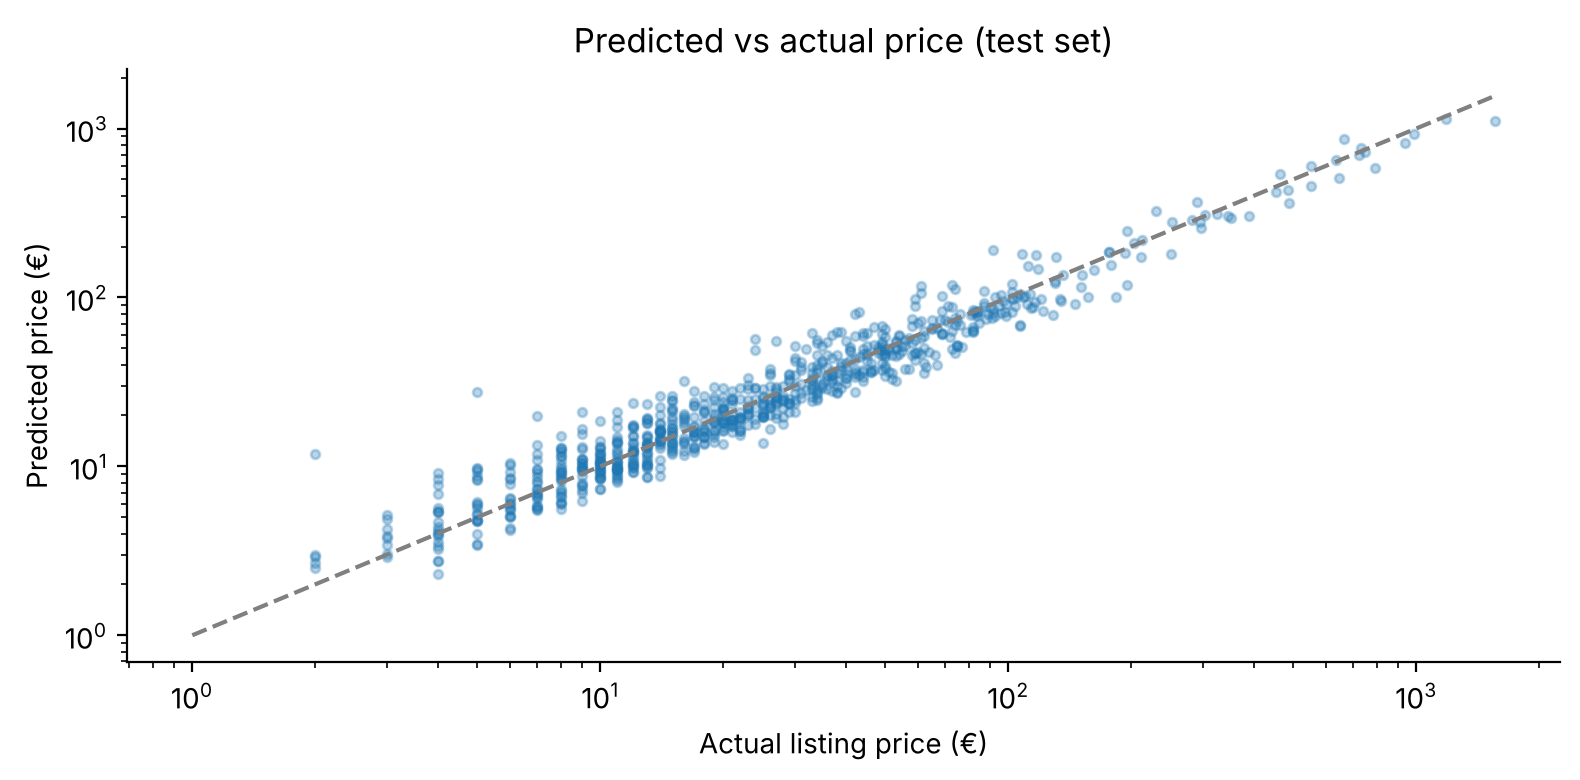

In [18]:
plt.scatter(actual, pred, alpha=0.3, s=10)
lim = [1, actual.max()]
plt.plot(lim, lim, color="grey", linestyle="--")
plt.xscale("log"); plt.yscale("log")
plt.xlabel("Actual listing price (€)")
plt.ylabel("Predicted price (€)")
plt.title("Predicted vs actual price (test set)")
plt.tight_layout()
plt.show()

## 6. Summary

- **Condition matters most.** Items that are new with tags keep about twice as much of their retail price as items in good condition.
- **Brand tier changes the picture.** Luxury and premium items keep a larger share of their value than high street items in the same condition.
- **Photos help.** Listings with more photos sell more often and faster.
- **Overpricing slows sales.** Items priced above the usual level for their tier and condition sell less often and take longer.
- **A simple model works well.** Brand tier, category, condition, photos and retail price explain most of the variation in listing price.

**Limitations:** the data is simulated, so these results show the method rather than real market behaviour. With real data, next steps would be adding seasonality, size and listing text, and testing a tree-based model.